# Fairness Analysis, Model Stability & Final Project Summary

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

---

## Notebook Objectives

The final stage of the project evaluates the credit risk scoring system from a fairness and business perspective.

The objectives are to:

- Analyze the distribution of predicted credit scores across demographic groups.
- Evaluate whether the model exhibits substantial differences between applicant segments.
- Assess the stability of the generated credit scores.
- Produce a fairness summary report.
- Present the final conclusions of the project.

This notebook completes the end-to-end credit risk scoring workflow by ensuring that model performance is complemented by fairness and interpretability analyses.

# Import Required Libraries

The following libraries are used for fairness analysis, descriptive statistics, visualization, and reporting.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Datasets

Two datasets are required:

- The applicant-level credit scores generated in Notebook 13.
- The original application dataset containing demographic information.

In [3]:
RESULT_DIR = Path("../results")

credit_scores = pd.read_csv(
    RESULT_DIR / "credit_risk_scores.csv"
)

application = pd.read_csv(
    "../data/HC_application_train.csv"
)

print("Credit Scores :", credit_scores.shape)
print("Application   :", application.shape)

Credit Scores : (61503, 6)
Application   : (307511, 122)


# Merge Applicant Information

The generated credit scores are merged with the original applicant demographic information using the applicant identifier (`SK_ID_CURR`).

In [4]:
fairness_df = application.merge(
    credit_scores,
    on="SK_ID_CURR",
    how="inner"
)

fairness_df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,Actual Default,Predicted Default,Default Probability,Credit Score,Risk Band
0,100009,0,Cash loans,F,Y,Y,1,171000.000,1560726.0,41301.0,...,0.0,0.0,1.0,1.0,2.0,0,0,0.008587,895,Excellent
1,100014,0,Cash loans,F,N,Y,1,112500.000,652500.0,21177.0,...,0.0,0.0,1.0,0.0,0.0,0,0,0.048031,871,Excellent
2,100015,0,Cash loans,F,N,Y,0,38419.155,148365.0,10678.5,...,0.0,0.0,0.0,0.0,2.0,0,0,0.024663,885,Excellent
3,100018,0,Cash loans,F,N,Y,0,189000.000,773680.5,32778.0,...,NaN,NaN,NaN,NaN,NaN,0,0,0.026232,884,Excellent
4,100020,0,Cash loans,M,N,N,0,108000.000,509602.5,26149.5,...,0.0,0.0,0.0,1.0,0.0,0,0,0.445537,633,Fair


# Dataset Overview

In [5]:
summary = pd.DataFrame({

    "Metric":[
        "Applicants",
        "Features"
    ],

    "Value":[
        fairness_df.shape[0],
        fairness_df.shape[1]
    ]

})

summary

,Metric,Value
0,Applicants,61503
1,Features,127


# Gender Fairness Analysis

The average default probability and average credit score are compared across gender groups.

In [6]:
gender_summary = (

    fairness_df

    .groupby("CODE_GENDER")

    .agg({

        "Default Probability":"mean",

        "Credit Score":"mean"

    })

    .round(2)

)

gender_summary

,Default Probability,Credit Score
CODE_GENDER,,
F,0.07,858.00
M,0.10,839.57
XNA,0.34,695.00


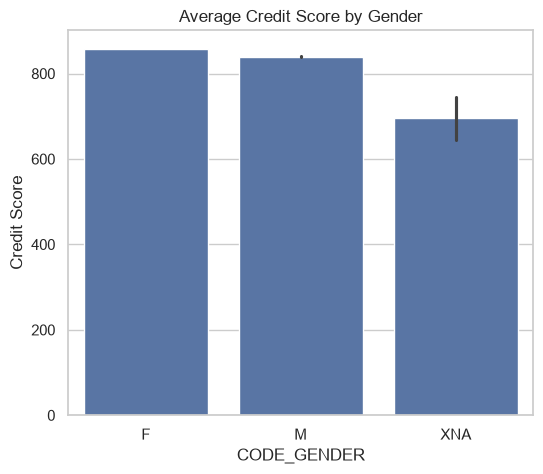

In [7]:
plt.figure(figsize=(6,5))

sns.barplot(

    data=fairness_df,

    x="CODE_GENDER",

    y="Credit Score"

)

plt.title("Average Credit Score by Gender")

plt.show()

# Income Type Fairness Analysis

Average default probabilities and credit scores are compared across applicant income categories.

In [8]:
income_summary = (

    fairness_df

    .groupby("NAME_INCOME_TYPE")

    .agg({

        "Default Probability":"mean",

        "Credit Score":"mean"

    })

    .round(2)

)

income_summary

,Default Probability,Credit Score
NAME_INCOME_TYPE,,
Businessman,0.04,876.00
Commercial associate,0.07,856.62
Maternity leave,0.08,849.50
Pensioner,0.05,867.41
State servant,0.07,856.91
Student,0.12,827.43
Unemployed,0.10,841.00
Working,0.09,843.27


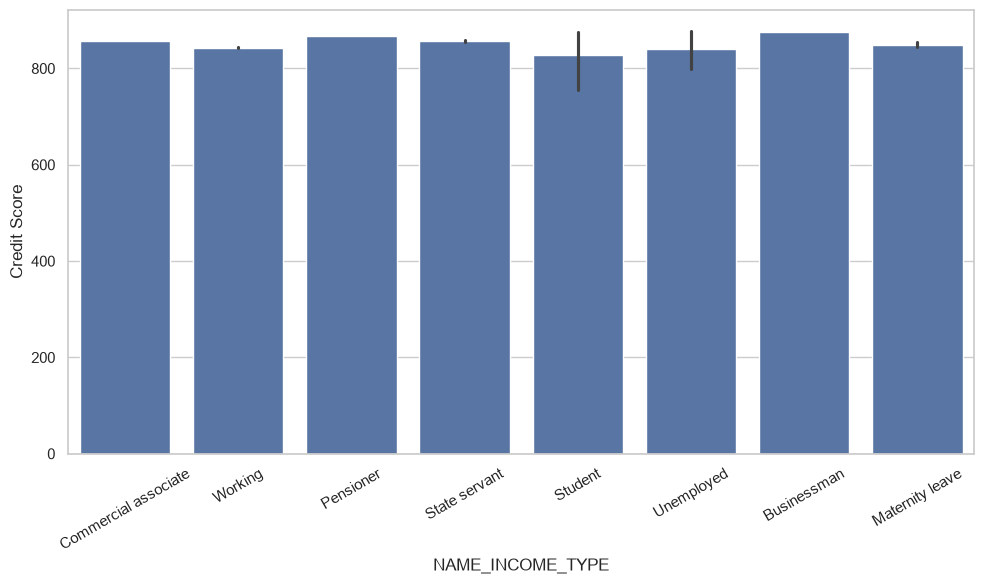

In [9]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=fairness_df,

    x="NAME_INCOME_TYPE",

    y="Credit Score"

)

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

# Education Level Fairness Analysis

The generated credit scores are analyzed across education categories.

In [10]:
education_summary = (

    fairness_df

    .groupby("NAME_EDUCATION_TYPE")

    .agg({

        "Default Probability":"mean",

        "Credit Score":"mean"

    })

    .round(2)

)

education_summary

,Default Probability,Credit Score
NAME_EDUCATION_TYPE,,
Academic degree,0.05,870.15
Higher education,0.05,867.67
Incomplete higher,0.08,849.65
Lower secondary,0.09,845.75
Secondary / secondary special,0.09,846.39


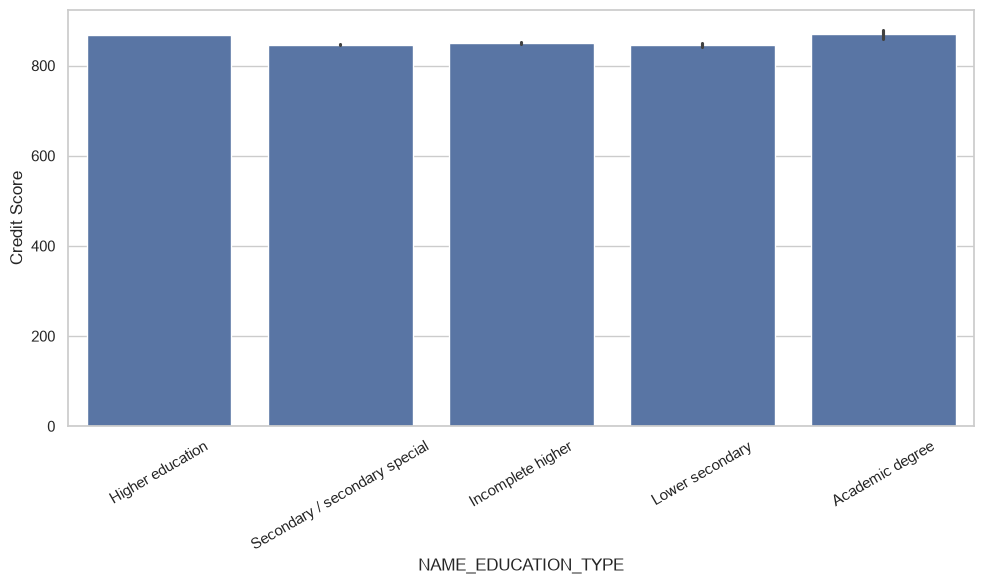

In [11]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=fairness_df,

    x="NAME_EDUCATION_TYPE",

    y="Credit Score"

)

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

# Risk Band Distribution

The distribution of applicants across credit risk bands is examined separately for each gender group.

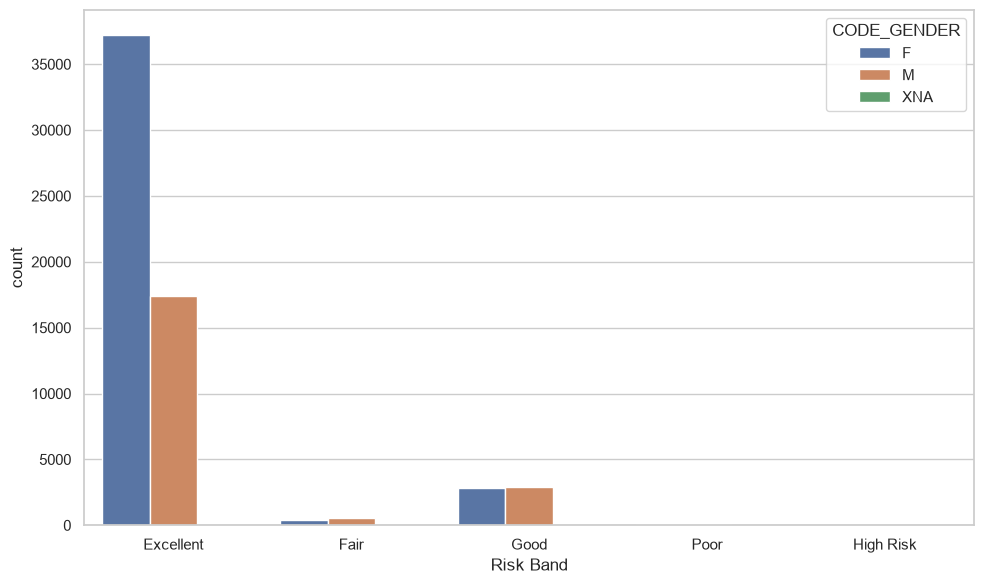

In [12]:
plt.figure(figsize=(10,6))

sns.countplot(

    data=fairness_df,

    x="Risk Band",

    hue="CODE_GENDER"

)

plt.tight_layout()

plt.show()

# Model Stability Analysis

The distribution of predicted default probabilities and generated credit scores provides insight into the consistency of the credit scoring system.

A stable model should produce a smooth distribution of scores without excessive clustering or abrupt discontinuities.

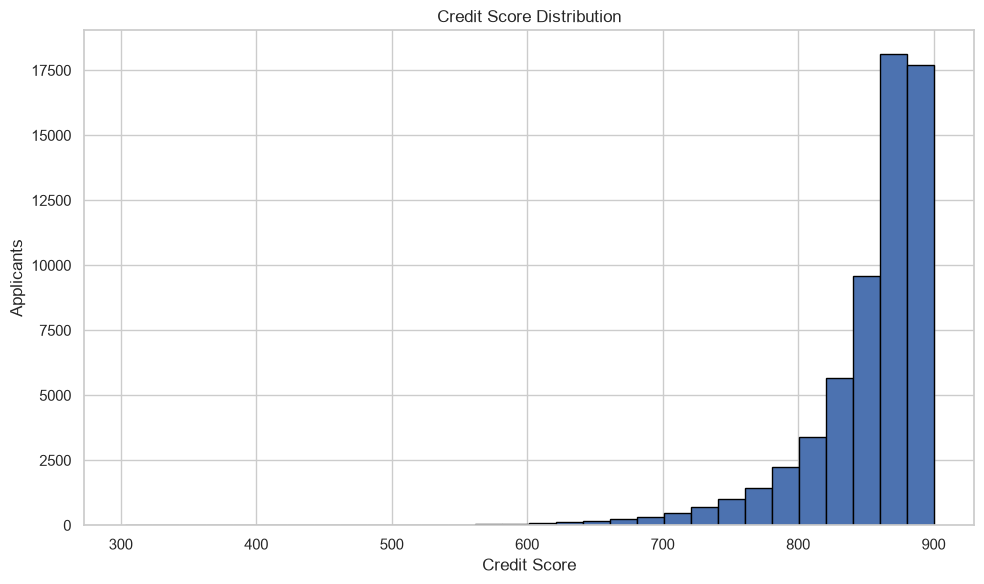

In [13]:
plt.figure(figsize=(10,6))

plt.hist(

    fairness_df["Credit Score"],

    bins=30,

    edgecolor="black"

)

plt.title("Credit Score Distribution")

plt.xlabel("Credit Score")

plt.ylabel("Applicants")

plt.tight_layout()

plt.show()

# Fairness Summary

The following tables summarize the fairness evaluation conducted across the selected demographic groups.

In [14]:
fairness_report = pd.concat(

    {

        "Gender": gender_summary,

        "Income": income_summary,

        "Education": education_summary

    }

)

fairness_report

Default Probability  Credit Score
Gender    F                                             0.07        858.00
          M                                             0.10        839.57
          XNA                                           0.34        695.00
Income    Businessman                                   0.04        876.00
          Commercial associate                          0.07        856.62
          Maternity leave                               0.08        849.50
          Pensioner                                     0.05        867.41
          State servant                                 0.07        856.91
          Student                                       0.12        827.43
          Unemployed                                    0.10        841.00
          Working                                       0.09        843.27
Education Academic degree                               0.05        870.15
          Higher education                              0.05        867.67
          Incomplete higher                             0.08        849.65
          Lower secondary                               0.09        845.75
          Secondary / secondary special                 0.09        846.39

# Save Fairness Report

The fairness analysis results are saved for documentation and future reference.

In [15]:
fairness_report.to_csv(

    RESULT_DIR / "fairness_report.csv"

)

print("Fairness report saved successfully.")

Fairness report saved successfully.


# Final Project Conclusion

## Project Summary

This project successfully developed an end-to-end Credit Risk Scoring System using multivariate statistical analysis and machine learning techniques.

### Key Accomplishments

- Collected and integrated multiple Home Credit datasets into a unified analytical dataset.
- Performed extensive data preprocessing, including missing value treatment and feature aggregation.
- Conducted exploratory data analysis to understand applicant characteristics and identify important trends.
- Applied hypothesis testing to evaluate statistically significant relationships between applicant attributes and loan default.
- Reduced feature dimensionality using Principal Component Analysis (PCA) to improve model efficiency and reduce multicollinearity.
- Developed and evaluated multiple classification models:
  - Logistic Regression
  - Decision Tree
  - K-Nearest Neighbors
  - Gaussian Naïve Bayes
  - Random Forest
  - XGBoost
  - LightGBM
- Selected the best-performing model based on evaluation metrics.
- Generated standardized credit scores on a 300–900 scale and categorized applicants into interpretable risk bands.
- Evaluated fairness and stability across demographic groups.

### Limitations

- The analysis was limited to historical applicant data provided by the Home Credit dataset.
- Fairness evaluation focused on descriptive comparisons and did not include advanced fairness metrics such as Demographic Parity or Equal Opportunity.
- Model performance may vary when applied to different populations or economic conditions.

### Future Work

Future enhancements may include:

- Hyperparameter optimization using Bayesian Optimization or Grid Search.
- Advanced feature engineering using domain-specific financial indicators.
- Incorporating Explainable AI (SHAP or LIME) to improve model interpretability.
- Evaluating additional fairness metrics and bias mitigation techniques.
- Deploying the credit scoring system as a web application or REST API.

---

## Project Status

**Completed Successfully**